<a href="https://colab.research.google.com/github/Aldyth11/PCVK_Ganjil_2026/blob/main/Week5_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'M. Aldyth Rafiansyah Fauzi'
NIM = '244107020179'
N = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : M. Aldyth Rafiansyah Fauzi
NIM    : 244107020179 | N = 179
bins   : 64
clip   : 3.0
tile   : 5
L      : 8
WAKTU  : 2026-09-22 13:07:56 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 81a7e233ab4357e9


> **E-1 PERCOBAAN HISTOGRAM**

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

<BarContainer object of 256 artists>

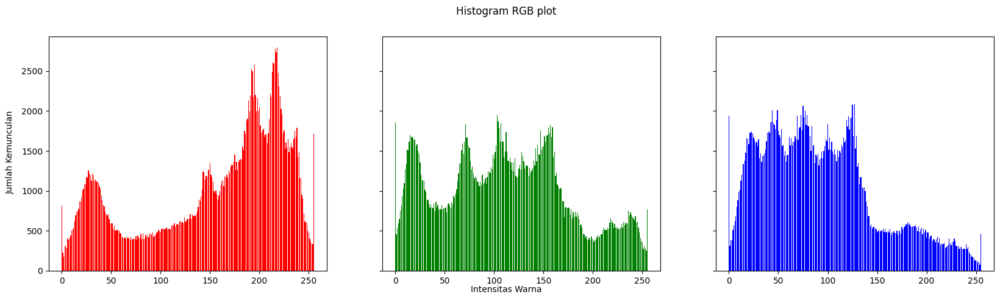

In [ ]:
# membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/PCVK2026/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(
    0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical'
)
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

<BarContainer object of 256 artists>

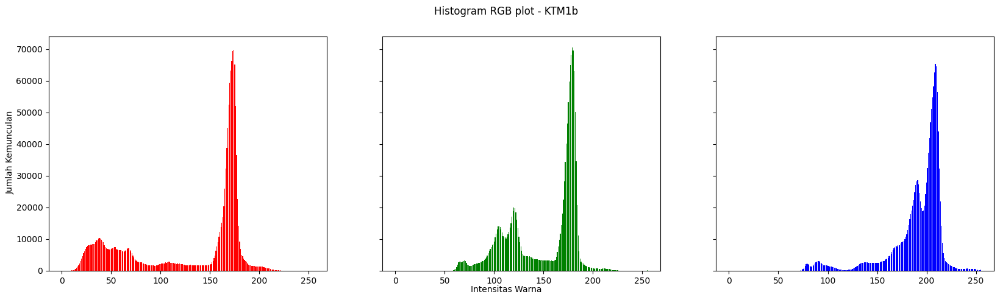

In [ ]:
# membuat histogram image (manual) - KTM1b.jpg
img = cv.imread('/content/drive/MyDrive/PCVK2026/KTM1b.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot - KTM1b')
fig.text(
    0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical'
)
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

> **PERTANYAAN PRAKTIKUM E1**

NO 1

In [ ]:
import cv2 as cv
import numpy as np

# 1. Baca citra lena.jpg
path_lena = '/content/drive/MyDrive/PCVK2026/lena.jpg'
img_lena = cv.imread(path_lena)
img_lena_rgb = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_lena_rgb)

# A. METODE 1: Manual
red_manual = [0] * 256
green_manual = [0] * 256
blue_manual = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red_manual[img_lena_rgb[y][x][0]] += 1
    green_manual[img_lena_rgb[y][x][1]] += 1
    blue_manual[img_lena_rgb[y][x][2]] += 1

red_manual = np.array(red_manual)
green_manual = np.array(green_manual)
blue_manual = np.array(blue_manual)

# B. METODE 2: numpy.histogram
red_np, _ = np.histogram(img_lena_rgb[:, :, 0], bins=256, range=(0, 256))
green_np, _ = np.histogram(img_lena_rgb[:, :, 1], bins=256, range=(0, 256))
blue_np, _ = np.histogram(img_lena_rgb[:, :, 2], bins=256, range=(0, 256))

# C. METODE 3: cv.calcHist
# Note: cv.calcHist menggunakan format BGR asli dari cv.imread
blue_cv = cv.calcHist([img_lena], [0], None, [256], [0, 256]).ravel()
green_cv = cv.calcHist([img_lena], [1], None, [256], [0, 256]).ravel()
red_cv = cv.calcHist([img_lena], [2], None, [256], [0, 256]).ravel()

# D. HITUNG SELISIH MAKSIMUM
diff_manual_np = np.max([
    np.max(np.abs(red_manual - red_np)),
    np.max(np.abs(green_manual - green_np)),
    np.max(np.abs(blue_manual - blue_np)),
])

diff_manual_cv = np.max([
    np.max(np.abs(red_manual - red_cv)),
    np.max(np.abs(green_manual - green_cv)),
    np.max(np.abs(blue_manual - blue_cv)),
])

diff_np_cv = np.max([
    np.max(np.abs(red_np - red_cv)),
    np.max(np.abs(green_np - green_cv)),
    np.max(np.abs(blue_np - blue_cv)),
])

print('=== HASIL PERBANDINGAN LENA.JPG ===')
print(f'Selisih Maksimum (Manual vs NumPy)  : {diff_manual_np}')
print(f'Selisih Maksimum (Manual vs OpenCV) : {diff_manual_cv}')
print(f'Selisih Maksimum (NumPy vs OpenCV)  : {diff_np_cv}')

=== HASIL PERBANDINGAN LENA.JPG ===
Selisih Maksimum (Manual vs NumPy)  : 0
Selisih Maksimum (Manual vs OpenCV) : 0.0
Selisih Maksimum (NumPy vs OpenCV)  : 0.0


In [ ]:
# 1. Baca citra KTM1b.jpg
path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1b.jpg'
img_ktm = cv.imread(path_ktm)
img_ktm_rgb = cv.cvtColor(img_ktm, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_ktm_rgb)

# A. METODE 1: Manual
red_manual = [0] * 256
green_manual = [0] * 256
blue_manual = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red_manual[img_ktm_rgb[y][x][0]] += 1
    green_manual[img_ktm_rgb[y][x][1]] += 1
    blue_manual[img_ktm_rgb[y][x][2]] += 1

red_manual = np.array(red_manual)
green_manual = np.array(green_manual)
blue_manual = np.array(blue_manual)

# B. METODE 2: numpy.histogram
red_np, _ = np.histogram(img_ktm_rgb[:, :, 0], bins=256, range=(0, 256))
green_np, _ = np.histogram(img_ktm_rgb[:, :, 1], bins=256, range=(0, 256))
blue_np, _ = np.histogram(img_ktm_rgb[:, :, 2], bins=256, range=(0, 256))

# C. METODE 3: cv.calcHist
blue_cv = cv.calcHist([img_ktm], [0], None, [256], [0, 256]).ravel()
green_cv = cv.calcHist([img_ktm], [1], None, [256], [0, 256]).ravel()
red_cv = cv.calcHist([img_ktm], [2], None, [256], [0, 256]).ravel()

# D. HITUNG SELISIH MAKSIMUM
diff_manual_np = np.max([
    np.max(np.abs(red_manual - red_np)),
    np.max(np.abs(green_manual - green_np)),
    np.max(np.abs(blue_manual - blue_np)),
])

diff_manual_cv = np.max([
    np.max(np.abs(red_manual - red_cv)),
    np.max(np.abs(green_manual - green_cv)),
    np.max(np.abs(blue_manual - blue_cv)),
])

diff_np_cv = np.max([
    np.max(np.abs(red_np - red_cv)),
    np.max(np.abs(green_np - green_cv)),
    np.max(np.abs(blue_np - blue_cv)),
])

print('=== HASIL PERBANDINGAN KTM1b.JPG ===')
print(f'Selisih Maksimum (Manual vs NumPy)  : {diff_manual_np}')
print(f'Selisih Maksimum (Manual vs OpenCV) : {diff_manual_cv}')
print(f'Selisih Maksimum (NumPy vs OpenCV)  : {diff_np_cv}')

=== HASIL PERBANDINGAN KTM1b.JPG ===
Selisih Maksimum (Manual vs NumPy)  : 0
Selisih Maksimum (Manual vs OpenCV) : 0.0
Selisih Maksimum (NumPy vs OpenCV)  : 0.0


NO 2

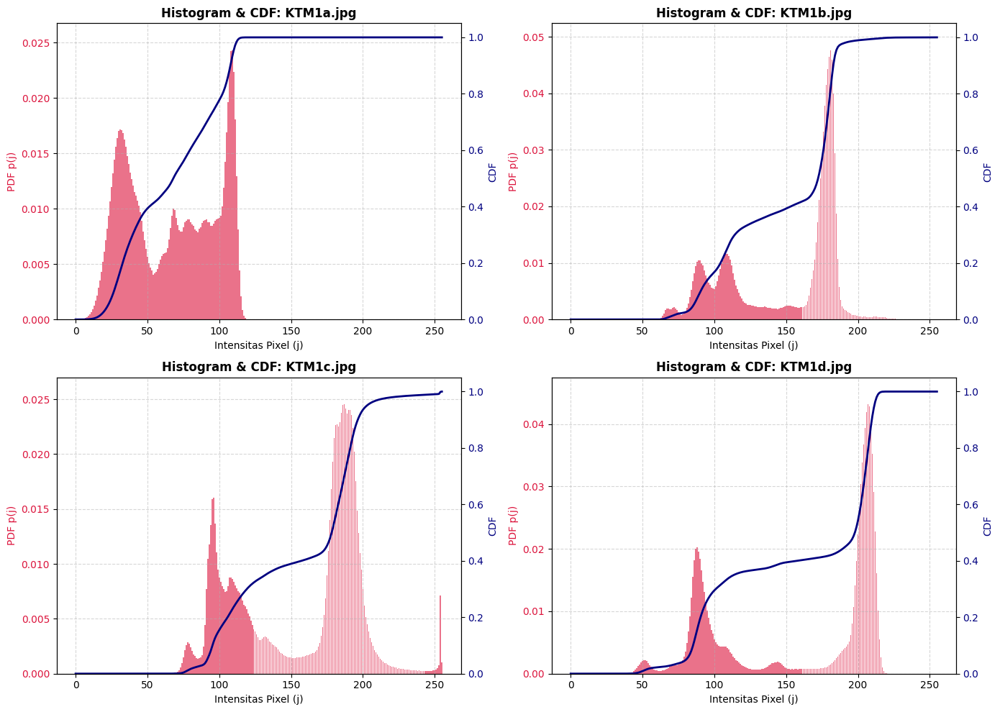

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Daftar nama file citra KTM
images = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
path_folder = '/content/drive/MyDrive/PCVK2026/'

# Buat figure 2x2
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.ravel()

for i, img_name in enumerate(images):
  # Read image dalam format Grayscale untuk analisis intensitas
  img_path = path_folder + img_name
  img = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

  if img is None:
    print(f'Gagal membaca file: {img_path}')
    continue

  # 1. Hitung Histogram Faktual & Normalisasi p(j)
  hist = cv.calcHist([img], [0], None, [256], [0, 256]).ravel()
  p_j = hist / img.size  # Normalisasi: p(j) = hist / total_pixel

  # 2. Hitung Cumulative Distribution Function (CDF)
  cdf = p_j.cumsum()

  # 3. Plot Histogram Normalisasi (Bar) & Kurva CDF (Line)
  ax1 = axs[i]
  color_hist = 'crimson'
  ax1.set_xlabel('Intensitas Pixel (j)', fontsize=10)
  ax1.set_ylabel('PDF p(j)', color=color_hist, fontsize=10)
  ax1.bar(
      np.arange(256), p_j, color=color_hist, alpha=0.6, label='Histogram p(j)'
  )
  ax1.tick_params(axis='y', labelcolor=color_hist)
  ax1.set_ylim([0, max(p_j) * 1.1])

  # Sumbu Y sekunder untuk CDF
  ax2 = ax1.twinx()
  color_cdf = 'navy'
  ax2.set_ylabel('CDF', color=color_cdf, fontsize=10)
  ax2.plot(
      np.arange(256), cdf, color=color_cdf, linewidth=2, label='Kurva CDF'
  )
  ax2.tick_params(axis='y', labelcolor=color_cdf)
  ax2.set_ylim([0, 1.05])

  ax1.set_title(f'Histogram & CDF: {img_name}', fontsize=12, fontweight='bold')
  ax1.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Analisis

- Citra Gelap (KTM1a.jpg): Piksel menumpuk di intensitas rendah (0-120). Kurva CDF melonjak tajam di awal dan langsung mendatar di nilai 1.0 pada intensitas ~115. Hal ini terjadi karena pencahayaan minim (underexposed) saat akuisisi.
- Citra Terang (KTM1d.jpg): Piksel menumpuk di intensitas tinggi (180-220). Kurva CDF landai di awal dan baru melonjak tajam mendekati batas kanan. Hal ini terjadi karena limpahan cahaya (overexposed) saat akuisisi.
- Kesimpulan: Jadi makin gelap citranya maka kurva CDF makin cepat naik ke puncak di area kiri. Sedangkan makin terang citra maka lonjakan kurva CDF bergeser ke area kanan.

NO 3

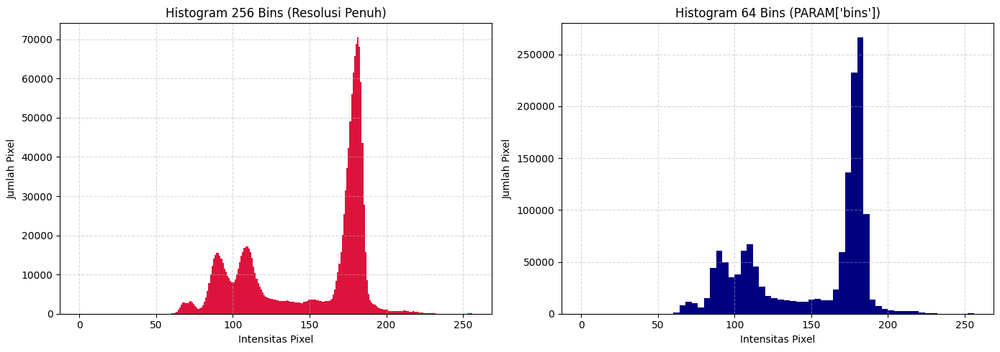

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Pastikan PARAM['bins'] sudah terdefinisi dari Sel Identitas Anda (NIM: 244107020179 -> N=179 -> bins=64)
bin_param = PARAM['bins']

# 1. Baca citra KTM1b.jpg (grayscale)
path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1b.jpg'
img_ktm = cv.imread(path_ktm, cv.IMREAD_GRAYSCALE)

if img_ktm is None:
  print('Gagal membaca gambar KTM1b.jpg! Cek lokasi path Anda.')
else:
  # 2. Plot Histogram Berdampingan (1 baris, 2 kolom)
  fig, axs = plt.subplots(1, 2, figsize=(14, 5))

  # Subplot 1: Histogram dengan 256 bin (Resolusi Penuh)
  axs[0].hist(img_ktm.ravel(), bins=256, range=[0, 256], color='crimson')
  axs[0].set_title('Histogram 256 Bins (Resolusi Penuh)')
  axs[0].set_xlabel('Intensitas Pixel')
  axs[0].set_ylabel('Jumlah Pixel')
  axs[0].grid(True, linestyle='--', alpha=0.5)

  # Subplot 2: Histogram dengan PARAM['bins'] (64 Bins)
  axs[1].hist(img_ktm.ravel(), bins=bin_param, range=[0, 256], color='navy')
  axs[1].set_title(f'Histogram {bin_param} Bins (PARAM[\'bins\'])')
  axs[1].set_xlabel('Intensitas Pixel')
  axs[1].set_ylabel('Jumlah Pixel')
  axs[1].grid(True, linestyle='--', alpha=0.5)

  plt.tight_layout()
  plt.show()

Analisisnya
- Histogram 256 Bins: Memiliki detail warna yang lengkap karena setiap nilai warna dari 0 sampai 255 dihitung satu per satu, sehingga bentuk grafiknya kelihatan mulus dan lekukan kecilnya kelihatan jelas.
- Histogram 64 Bins: Tiap 4 nilai warna digabung jadi 1 kelompok, jadi detail grafiknya berkurang dan bentuknya kelihatan lebih kotak-kotak/kasar.

informasi yang hilang saat jumlah bin dikurangi
- Detail grafiknya jadi kasar: Warna-warna yang tadinya beda tipis sekarang dipaksa masuk ke satu wadah (bin) yang sama, jadi grafik yang tadinya mulus berubah jadi kotak-kotak.
- Titik puncaknya jadi gak pasti: Kita gak bisa tahu lagi nilai persis dari puncak teratasnya, cuma bisa tahu kisaran/ancer-ancer nilainya aja.
- Bedanya terang-gelap yang tipis jadi hilang: Gambar yang beda tipis terang-gelapnya jadi kelihatan sama rata gara-gara nilainya digabung.

> **E-2 PERCOBAAN HISTOGRAM EQUALIZATION**

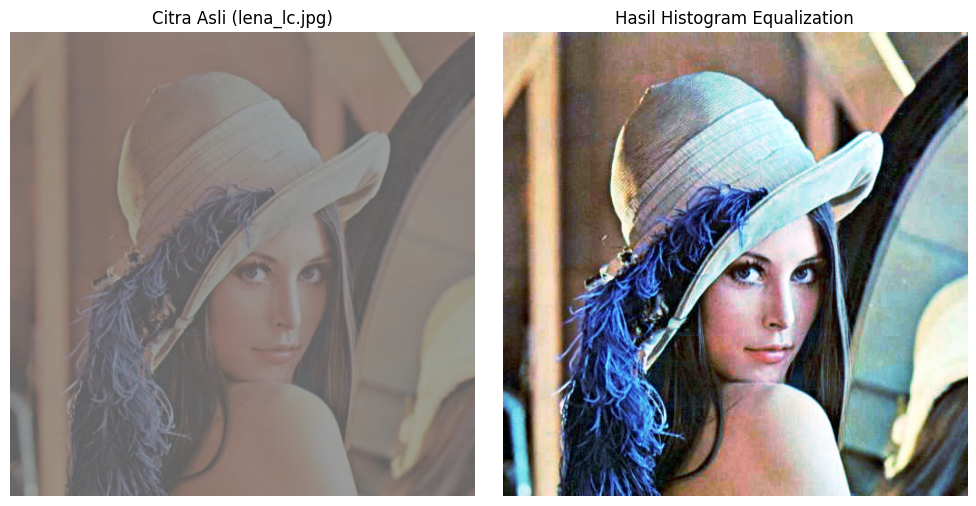

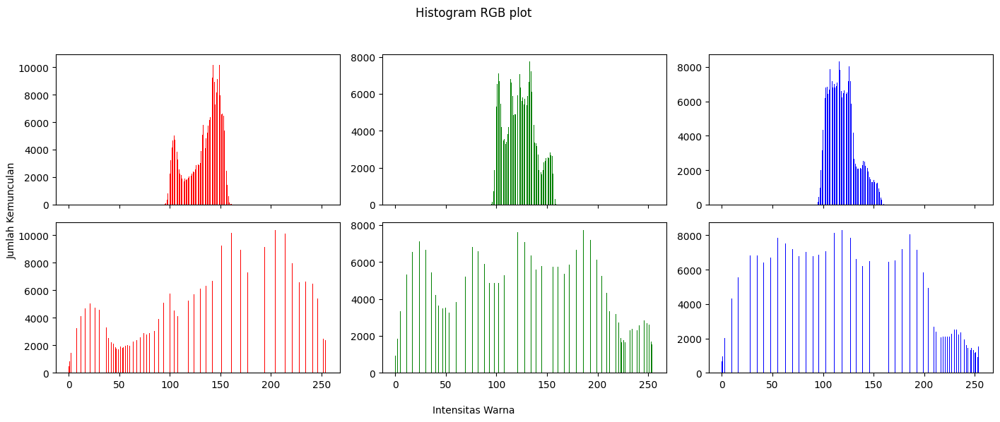

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca Citra lena_lc.jpg
path_lena_lc = '/content/drive/MyDrive/PCVK2026/lena_lc.jpg'
img_bgr = cv.imread(path_lena_lc)

if img_bgr is None:
  print('Gagal membaca gambar lena_lc.jpg! Periksa lokasi path Anda.')
else:
  # Konversi BGR ke RGB
  img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
  height, width, _ = img_rgb.shape
  total_pixel = height * width

  # Matriks penampung citra hasil equalization
  img_equalized = np.zeros_like(img_rgb)

  hist_before = np.zeros((3, 256), dtype=int)
  hist_after = np.zeros((3, 256), dtype=int)

  # 2. Proses Histogram Equalization Per Channel (R, G, B)
  for c in range(3):
    channel = img_rgb[:, :, c]

    # Hitung Histogram Sebelum (Baris 1)
    for y in range(height):
      for x in range(width):
        hist_before[c][channel[y][x]] += 1

    # Hitung CDF (Penjumlahan Kumulatif)
    cdf = np.cumsum(hist_before[c])

    # Rumus Standard Equalization
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / ((total_pixel) - cdf_m.min())
    map_eq = np.ma.filled(cdf_m, 0).astype('uint8')

    # Transformasi nilai pixel ke citra baru
    channel_eq = map_eq[channel]
    img_equalized[:, :, c] = channel_eq

    # Hitung Histogram Sesudah (Baris 2)
    for y in range(height):
      for x in range(width):
        hist_after[c][channel_eq[y][x]] += 1

  # DISPLAY 1: GAMBAR SEBELUM & SESUDAH
  fig, axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].imshow(img_rgb)
  axs[0].set_title('Citra Asli (lena_lc.jpg)')
  axs[0].axis('off')

  axs[1].imshow(img_equalized)
  axs[1].set_title('Hasil Histogram Equalization')
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()

  # DISPLAY 2: HISTOGRAM RGB PLOT (2x3)
  names = np.arange(256)
  fig, axs = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
  fig.suptitle('Histogram RGB plot')

  colors = ['red', 'green', 'blue']

  for c in range(3):
    # Baris 1: Sebelum Equalization
    axs[0, c].bar(names, hist_before[c], color=colors[c], width=0.6)
    # Baris 2: Sesudah Equalization
    axs[1, c].bar(names, hist_after[c], color=colors[c], width=0.6)

  fig.text(
      0.06, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical'
  )
  fig.text(0.5, 0.02, 'Intensitas Warna', ha='center')

  plt.tight_layout(rect=[0.06, 0.05, 1, 0.95])
  plt.show()

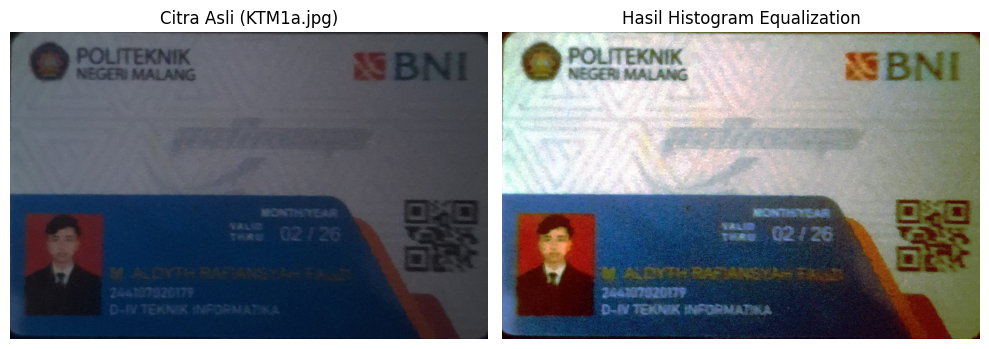

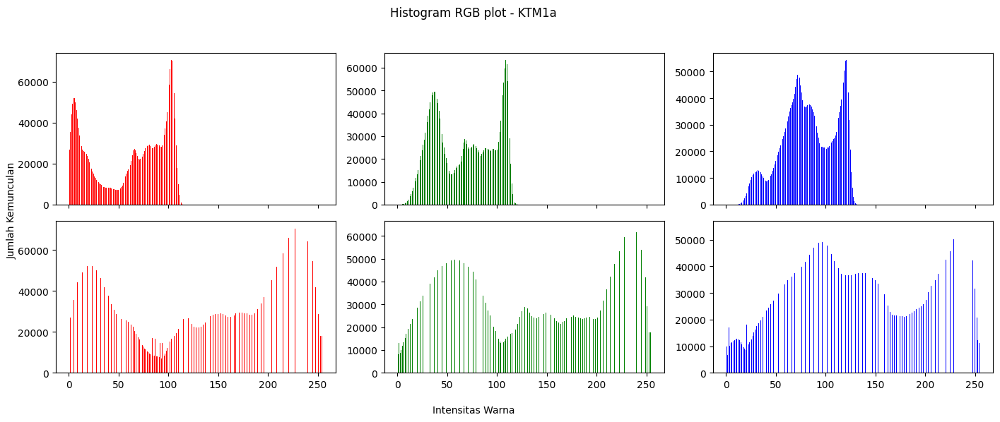

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca Citra KTM1a.jpg (Ruangan Gelap)
path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1a.jpg'
img_bgr = cv.imread(path_ktm)

if img_bgr is None:
  print('Gagal membaca gambar KTM1a.jpg! Periksa lokasi path Anda.')
else:
  # Konversi BGR ke RGB
  img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
  height, width, _ = img_rgb.shape
  total_pixel = height * width

  # Matriks penampung citra hasil equalization
  img_equalized = np.zeros_like(img_rgb)

  hist_before = np.zeros((3, 256), dtype=int)
  hist_after = np.zeros((3, 256), dtype=int)

  # 2. Proses Histogram Equalization Per Channel (R, G, B)
  for c in range(3):
    channel = img_rgb[:, :, c]

    # Hitung Histogram Sebelum (Baris 1)
    for y in range(height):
      for x in range(width):
        hist_before[c][channel[y][x]] += 1

    # Hitung CDF (Penjumlahan Kumulatif)
    cdf = np.cumsum(hist_before[c])

    # Rumus Standard Equalization
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / ((total_pixel) - cdf_m.min())
    map_eq = np.ma.filled(cdf_m, 0).astype('uint8')

    # Transformasi nilai pixel ke citra baru
    channel_eq = map_eq[channel]
    img_equalized[:, :, c] = channel_eq

    # Hitung Histogram Sesudah (Baris 2)
    for y in range(height):
      for x in range(width):
        hist_after[c][channel_eq[y][x]] += 1

  # DISPLAY 1: GAMBAR SEBELUM & SESUDAH
  fig, axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].imshow(img_rgb)
  axs[0].set_title('Citra Asli (KTM1a.jpg)')
  axs[0].axis('off')

  axs[1].imshow(img_equalized)
  axs[1].set_title('Hasil Histogram Equalization')
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()

  # DISPLAY 2: HISTOGRAM RGB PLOT (2x3)
  names = np.arange(256)
  fig, axs = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
  fig.suptitle('Histogram RGB plot - KTM1a')

  colors = ['red', 'green', 'blue']

  for c in range(3):
    # Baris 1: Sebelum Equalization
    axs[0, c].bar(names, hist_before[c], color=colors[c], width=0.6)
    # Baris 2: Sesudah Equalization
    axs[1, c].bar(names, hist_after[c], color=colors[c], width=0.6)

  fig.text(
      0.06, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical'
  )
  fig.text(0.5, 0.02, 'Intensitas Warna', ha='center')

  plt.tight_layout(rect=[0.06, 0.05, 1, 0.95])
  plt.show()

NO 2

=== PERBANDINGAN: lena_lc.jpg ===
Selisih Maksimum Piksel (Manual vs OpenCV): 1
---------------------------------------------


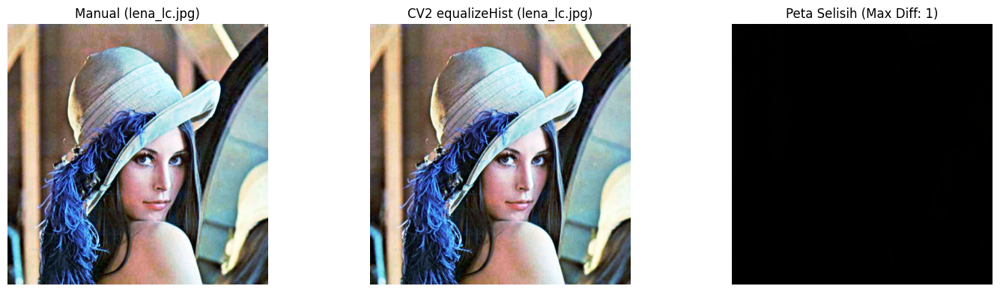

=== PERBANDINGAN: KTM1a.jpg ===
Selisih Maksimum Piksel (Manual vs OpenCV): 1
---------------------------------------------


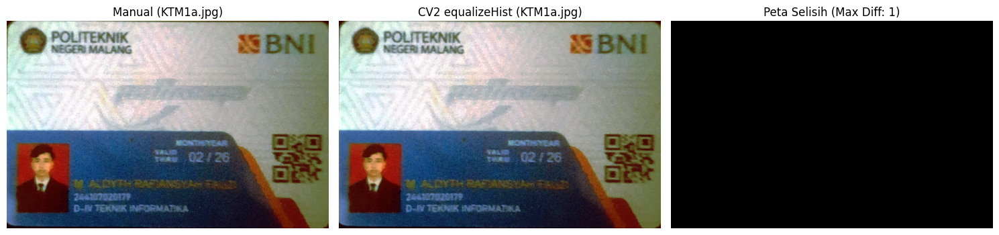

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np


def run_equalization_comparison(image_path, title_name):
  # 1. Baca Citra BGR
  image = cv.imread(image_path)
  if image is None:
    print(f'Gagal membaca citra: {image_path}')
    return

  height, width, _ = image.shape
  total_pixel = height * width

  # A. IMPLEMENTASI CV2.EQUALIZEHIST (OPENCV)
  # Sesuai potongan kode pada modul
  b, g, r = cv.split(image)

  b_equalized = cv.equalizeHist(b)
  g_equalized = cv.equalizeHist(g)
  r_equalized = cv.equalizeHist(r)

  # Gabungkan kembali channel hasil equalizeHist (BGR -> RGB untuk display)
  img_cv2_bgr = cv.merge([b_equalized, g_equalized, r_equalized])
  img_cv2_rgb = cv.cvtColor(img_cv2_bgr, cv.COLOR_BGR2RGB)

  # B. IMPLEMENTASI MANUAL (FLOWCHART MODUL)
  img_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
  img_manual_rgb = np.zeros_like(img_rgb)

  for c in range(3):
    channel = img_rgb[:, :, c]

    # Hitung Frekuensi
    hist = np.zeros(256, dtype=int)
    for y in range(height):
      for x in range(width):
        hist[channel[y][x]] += 1

    # Hitung CDF Kumulatif & Mapping Normalisasi
    cdf = np.cumsum(hist)
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (total_pixel - cdf_m.min())
    map_eq = np.ma.filled(cdf_m, 0).astype('uint8')

    img_manual_rgb[:, :, c] = map_eq[channel]

  # C. HITUNG SELISIH MAKSIMUM
  # Hitung beda absolut antarpiksel
  diff_image = np.abs(
      img_manual_rgb.astype(np.int16) - img_cv2_rgb.astype(np.int16)
  )
  max_diff = np.max(diff_image)

  print(f'=== PERBANDINGAN: {title_name} ===')
  print(f'Selisih Maksimum Piksel (Manual vs OpenCV): {max_diff}')
  print('-' * 45)

  # D. TAMPILAN GRAFIS & HISTOGRAM
  fig, axs = plt.subplots(1, 3, figsize=(15, 4))
  axs[0].imshow(img_manual_rgb)
  axs[0].set_title(f'Manual ({title_name})')
  axs[0].axis('off')

  axs[1].imshow(img_cv2_rgb)
  axs[1].set_title(f'CV2 equalizeHist ({title_name})')
  axs[1].axis('off')

  axs[2].imshow(diff_image.astype(np.uint8), cmap='hot')
  axs[2].set_title(f'Peta Selisih (Max Diff: {max_diff})')
  axs[2].axis('off')

  plt.tight_layout()
  plt.show()


# Jalankan untuk kedua citra
run_equalization_comparison(
    '/content/drive/MyDrive/PCVK2026/lena_lc.jpg', 'lena_lc.jpg'
)
run_equalization_comparison(
    '/content/drive/MyDrive/PCVK2026/KTM1a.jpg', 'KTM1a.jpg'
)

Hasil perbandingan menunjukkan selisih maksimum antara metode manual dan cv2.equalizeHist hanya sebesar 1. Hal ini membuktikan implementasi manual telah berjalan benar dan selisih sebesar 1 tersebut terjadi karena perbedaan teknik pembulatan desimal (rounding) antara Python/NumPy dan pustaka internal C++ OpenCV.

NO 3

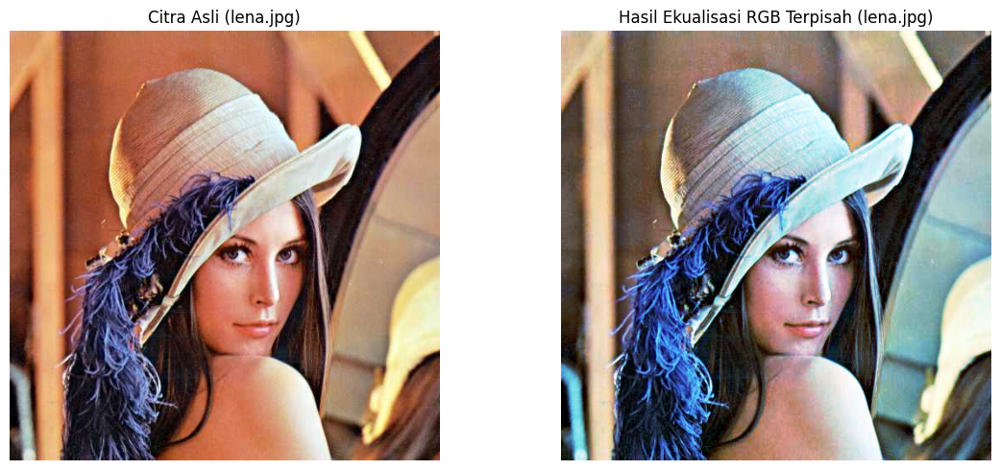

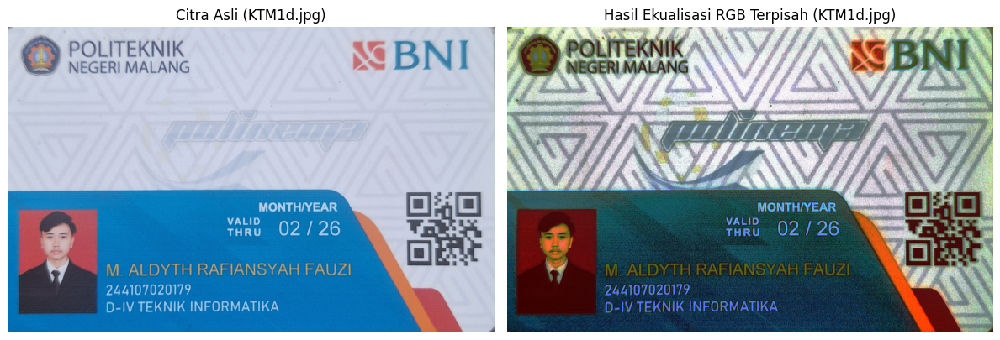

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Definisi PATH/folder sesuai environment Anda
BASE_PATH = '/content/drive/MyDrive/PCVK2026'


def ekualisasi_rgb_terpisah(image_path, title_name):
  # 1. Baca Citra BGR
  bgr = cv.imread(image_path)

  if bgr is None:
    print(f'Gagal membaca file dari path: {image_path}')
    return

  # Konversi ke RGB untuk tampilan asli Matplotlib
  rgb_original = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)

  # 2. Cara 1: Tiap kanal diekualisasi sendiri-sendiri (sesuai potongan kode modul)
  kanal = list(cv.split(bgr))
  for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])

  # Merge kembali channel yang sudah diekualisasi
  he_bgr = cv.merge(kanal)
  he_rgb = cv.cvtColor(he_bgr, cv.COLOR_BGR2RGB)

  # 3. Visualisasi Perbandingan Citra
  fig, axs = plt.subplots(1, 2, figsize=(12, 5))

  axs[0].imshow(rgb_original)
  axs[0].set_title(f'Citra Asli ({title_name})')
  axs[0].axis('off')

  axs[1].imshow(he_rgb)
  axs[1].set_title(f'Hasil Ekualisasi RGB Terpisah ({title_name})')
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()


# --- TAHAP 1: Citra Contoh lena.jpg ---
ekualisasi_rgb_terpisah(f'{BASE_PATH}/lena.jpg', 'lena.jpg')

# --- TAHAP 2: Citra KTM1d.jpg ---
ekualisasi_rgb_terpisah(f'{BASE_PATH}/KTM1d.jpg', 'KTM1d.jpg')

Mengekualisasi kanal BGR/RGB satu per satu bukan metode yang ideal untuk citra berwarna karena dapat merusak rona warna alami. Solusi yang lebih baik untuk citra berwarna adalah mengonversi citra ke ruang warna terpisah antara intensitas cahaya dan warna, seperti HSV (mengekualisasi kanal Value/V saja) atau YCrCb (mengekualisasi kanal Luminance/Y saja).

NO 4

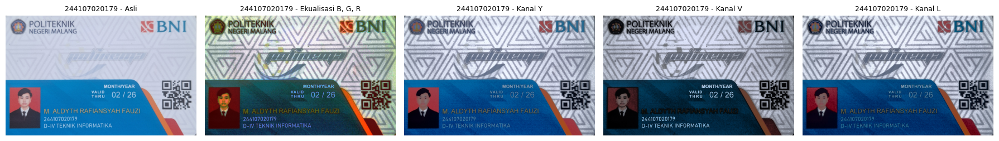


=== TABEL HASIL EKUALISASI ===
Cara                    geser Hue (der)    rerata terang
Asli                               0.00            159.9
Ekualisasi B, G, R                53.39            127.7
Kanal Y                            3.16            133.2
Kanal V                            1.45            110.6
Kanal L                            4.91            124.0
CLAHE Kanal L                      1.24            156.2


In [2]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Parameter NIM Aldyth (NIM: 244107020179)
PARAM = {'bins': 64, 'clip': 2.0, 'tile': 3, 'L': 8}

# 1. Load Citra KTM1d.jpg
path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1d.jpg'
bgr = cv.imread(path_ktm)

if bgr is None:
  print(f'Gagal membaca file dari path: {path_ktm}')
else:
  # --- CARA 1: Ekualisasi B, G, R Terpisah ---
  kanal = list(cv.split(bgr))
  for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])
  he_rgb = cv.merge(kanal)

  # --- CARA 2: Ekualisasi Kanal Terang pada Ruang Warna Berbeda ---
  # YCrCb
  ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
  y, cr, cb = cv.split(ycrcb)
  he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

  # HSV
  hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
  h, sat, v = cv.split(hsv)
  he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

  # LAB
  lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
  l, a, b = cv.split(lab)
  he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

  # --- CARA 3: CLAHE pada Kanal L (LAB) ---
  clahe = cv.createCLAHE(
      clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile'])
  )
  clahe_l = cv.cvtColor(cv.merge([clahe.apply(l), a, b]), cv.COLOR_LAB2BGR)

  # VISUALISASI 5 CITRA BERDAMPINGAN
  NIM = '244107020179'
  judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
  citra = [bgr, he_rgb, he_y, he_v, he_l]

  plt.figure(figsize=(18, 4))
  for i, (c, t) in enumerate(zip(citra, judul), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.axis('off')
  plt.tight_layout()
  plt.show()

  # PERHITUNGAN PERGESERAN HUE & RERATA TERANG
  def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)  # Hue melingkar 0-179
    return d.mean()

  print('\n=== TABEL HASIL EKUALISASI ===')
  print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
  for t, c in zip(judul + ['CLAHE Kanal L'], citra + [clahe_l]):
    deg = geser_hue(bgr, c) * 2
    brightness = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
    print('%-22s %16.2f %16.1f' % (t, deg, brightness))

Jawaban Pertanyaan

1. Pergeseran Hue Terbesar
- Cara: Ekualisasi B, G, R terpisah.
- Nilai: 53.39 derajat.
- Sebab: Rasio gabungan warna RGB rusak karena tiap kanal dihitung dan diubah secara independen.

2. Sebab Pergeseran Hue Tidak Nol pada Kanal Terang
- Saat dikembalikan dari Y/V/L ke BGR, koordinat warna dihitung ulang lewat konversi matematis.
- Hasil konversi tersebut mengalami pembulatan desimal (rounding) dan pemotongan nilai (clipping ke rentang 0 sampai 255) pada format uint8, sehingga nilai RGB hasil sedikit bergeser dari rasio awalnya.

3. Kanal Terbaik untuk Foto KTM (Y vs V vs L)
- Pilihan: Kanal L (LAB) atau Kanal Y (YCrCb).
- Alasan: Ruang warna LAB memisahkan kecerahan dan warna secara sempurna. Kanal V (HSV) membuat citra menjadi jauh lebih gelap (rerata 110.6) dan warnanya terlalu jenuh.
- Bukti Visual: Pada Kanal L, warna kulit pasfoto tidak pucat/belang, warna logo BNI/Polinema tetap akurat, dan teks NIM/Nama lebih mudah dibaca.

4. Perbandingan equalizeHist vs CLAHE (Kanal L)
- Pergeseran Hue: CLAHE jauh lebih kecil (1.24 derajat vs 4.91 derajat).
- Rerata Kecerahan: equalizeHist menurunkan kecerahan secara drastis ke 124.0, sedangkan CLAHE mampu menjaga tingkat kecerahan tetap alami mirip citra asli (156.2 vs 159.9).
- Hasil: CLAHE berhasil menajamkan detail teks dan foto tanpa menimbulkan noise berlebih atau membuat citra menjadi gelap.

> **PERTANYAAN PRAKTIKUM E2**

NO 1

=== HASIL PERHITUNGAN PSNR & MSE ===
PSNR Citra Asli vs Manual  : 10.57 dB (MSE: 5706.05)
PSNR Citra Asli vs OpenCV  : 10.57 dB (MSE: 5706.05)



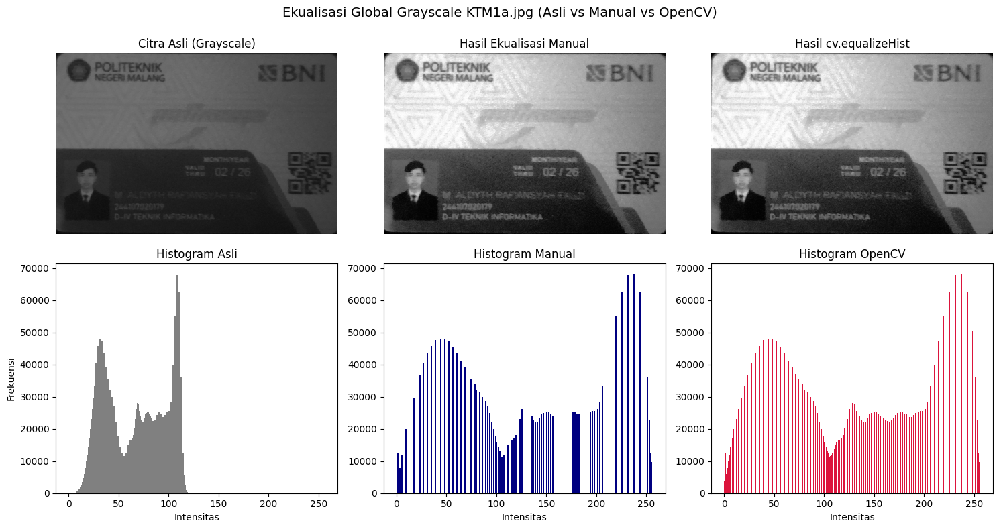

In [3]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Read KTM1a.jpg dalam format Grayscale (Langkah 1a)
path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1a.jpg'
img_gray = cv.imread(path_ktm, cv.IMREAD_GRAYSCALE)

if img_gray is None:
  print('Gagal membaca citra KTM1a.jpg! Periksa kembali path lokasi Anda.')
else:
  height, width = img_gray.shape
  total_pixel = height * width

  # --- A. Ekualisasi Manual ---
  hist_manual = [0] * 256
  for y in range(height):
    for x in range(width):
      hist_manual[img_gray[y][x]] += 1

  cdf = [0] * 256
  cumulative_sum = 0
  for i in range(256):
    cumulative_sum += hist_manual[i]
    cdf[i] = cumulative_sum / total_pixel

  map_eq = [round(cdf[i] * 255) for i in range(256)]

  img_manual = np.zeros_like(img_gray)
  for y in range(height):
    for x in range(width):
      img_manual[y][x] = map_eq[img_gray[y][x]]

  # --- B. Ekualisasi cv.equalizeHist ---
  img_cv2 = cv.equalizeHist(img_gray)

  # --- C. Perhitungan PSNR (Langkah 1c) ---
  def hitung_psnr(asli, hasil):
    mse = np.mean((asli.astype(np.float64) - hasil.astype(np.float64)) ** 2)
    if mse == 0:
      return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr, mse

  psnr_manual, mse_manual = hitung_psnr(img_gray, img_manual)
  psnr_cv2, mse_cv2 = hitung_psnr(img_gray, img_cv2)

  print(f'=== HASIL PERHITUNGAN PSNR & MSE ===')
  print(f'PSNR Citra Asli vs Manual  : {psnr_manual:.2f} dB (MSE: {mse_manual:.2f})')
  print(f'PSNR Citra Asli vs OpenCV  : {psnr_cv2:.2f} dB (MSE: {mse_cv2:.2f})\n')

  # DISPLAY SATELLITE LAYOUT (Langkah 1b)
  # Displays original image, equalized images, and histogram
  fig, axs = plt.subplots(2, 3, figsize=(15, 8))
  fig.suptitle(
      'Ekualisasi Global Grayscale KTM1a.jpg (Asli vs Manual vs OpenCV)',
      fontsize=14,
  )

  # Baris 1: Citra Visual
  axs[0, 0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
  axs[0, 0].set_title('Citra Asli (Grayscale)')
  axs[0, 0].axis('off')

  axs[0, 1].imshow(img_manual, cmap='gray', vmin=0, vmax=255)
  axs[0, 1].set_title('Hasil Ekualisasi Manual')
  axs[0, 1].axis('off')

  axs[0, 2].imshow(img_cv2, cmap='gray', vmin=0, vmax=255)
  axs[0, 2].set_title('Hasil cv.equalizeHist')
  axs[0, 2].axis('off')

  # Baris 2: Histogram
  axs[1, 0].hist(img_gray.ravel(), bins=256, range=[0, 256], color='gray')
  axs[1, 0].set_title('Histogram Asli')
  axs[1, 0].set_xlabel('Intensitas')
  axs[1, 0].set_ylabel('Frekuensi')

  axs[1, 1].hist(img_manual.ravel(), bins=256, range=[0, 256], color='navy')
  axs[1, 1].set_title('Histogram Manual')
  axs[1, 1].set_xlabel('Intensitas')

  axs[1, 2].hist(img_cv2.ravel(), bins=256, range=[0, 256], color='crimson')
  axs[1, 2].set_title('Histogram OpenCV')
  axs[1, 2].axis('on')
  axs[1, 2].set_xlabel('Intensitas')

  plt.tight_layout()
  plt.show()

Analisis Jawaban Pertanyaan 1c

1. Penyebab Nilai PSNR Turun Padahal Citra Terlihat Lebih Jelas
Nilai PSNR (Peak Signal-to-Noise Ratio) dihitung berbasis MSE (Mean Squared Error), yaitu mengukur besarnya perubahan nilai piksel antara citra asli dan citra hasil.

- PSNR berfungsi mengukur tingkat kemiripan matematis. Semakin mirip nilai pikselnya dengan citra asli, nilai PSNR akan semakin tinggi.
- Proses ekualisasi histogram bertujuan merentangkan dan meratakan distribusi intensitas piksel (membuat area gelap menjadi lebih terang dan kontras meningkat).
- Karena banyak piksel yang nilainya diubah secara drastis dari kondisi aslinya, nilai MSE menjadi sangat besar. Hal inilah yang menyebabkan nilai PSNR menurun tajam, meskipun secara visual gambar terlihat lebih terang dan teks pada KTM menjadi jauh lebih jelas.

2. Kesimpulan: Kelayakan PSNR untuk Menilai Keterbacaan Citra
PSNR tidak layak digunakan untuk menilai keterbacaan sebuah citra.

- Alasan: PSNR hanya mengukur tingkat kemiripan fisis (matematis) piksel, bukan tingkat kualitas persepsi visual mata manusia (Human Visual System).
- PSNR menganggap perbaikan kontras sebagai sebuah kesalahan (error) karena nilainya berbeda dari citra asli.
- Untuk menilai keterbacaan teks atau dokumen seperti KTM, metrik yang lebih tepat digunakan adalah SSIM (Structural Similarity Index Measure) atau pengujian akurasi pembacaan karakter menggunakan OCR (Optical Character Recognition).

NO 2

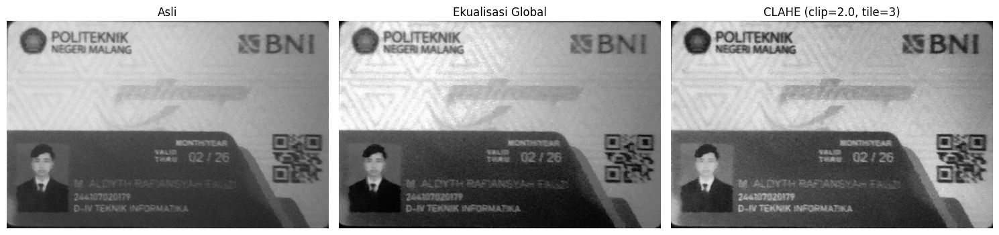

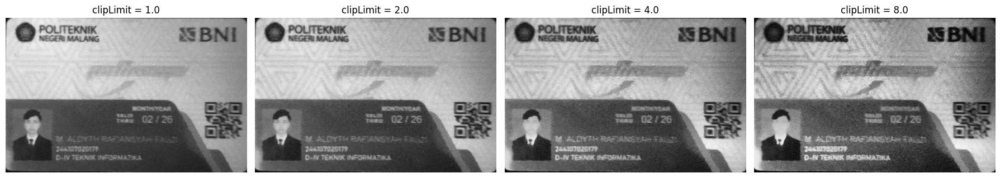

In [4]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

PARAM = {'bins': 64, 'clip': 2.0, 'tile': 3, 'L': 8}

path_ktm = '/content/drive/MyDrive/PCVK2026/KTM1a.jpg'
img_gray = cv.imread(path_ktm, cv.IMREAD_GRAYSCALE)

if img_gray is None:
  print('Gagal membaca citra KTM1a.jpg!')
else:
  # Ekualisasi Global untuk Perbandingan
  he_global = cv.equalizeHist(img_gray)

  # --- TAHAP 2a: CLAHE Default Parameter ---
  clahe_default = cv.createCLAHE(
      clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile'])
  )
  img_clahe_default = clahe_default.apply(img_gray)

  # Display Perbandingan Global vs CLAHE
  fig, axs = plt.subplots(1, 3, figsize=(15, 5))
  axs[0].imshow(img_gray, cmap='gray')
  axs[0].set_title('Asli')
  axs[0].axis('off')

  axs[1].imshow(he_global, cmap='gray')
  axs[1].set_title('Ekualisasi Global')
  axs[1].axis('off')

  axs[2].imshow(img_clahe_default, cmap='gray')
  axs[2].set_title(f"CLAHE (clip={PARAM['clip']}, tile={PARAM['tile']})")
  axs[2].axis('off')

  plt.tight_layout()
  plt.show()

  # --- TAHAP 2b: Variasi 3 Nilai clipLimit ---
  clips = [1.0, 2.0, 4.0, 8.0]
  clahe_results = []

  for c in clips:
    clahe_obj = cv.createCLAHE(
        clipLimit=c, tileGridSize=(PARAM['tile'], PARAM['tile'])
    )
    clahe_results.append(clahe_obj.apply(img_gray))

  # Display Variasi clipLimit
  fig, axs = plt.subplots(1, 4, figsize=(18, 5))
  for i, (c, res) in enumerate(zip(clips, clahe_results)):
    axs[i].imshow(res, cmap='gray')
    axs[i].set_title(f'clipLimit = {c}')
    axs[i].axis('off')

  plt.tight_layout()
  plt.show()

Jawaban Pertanyaan 2

2a. Perbandingan Keterbacaan NIM dan Nama (Global vs CLAHE)
- Hasil Keterbacaan Terbaik: CLAHE (clip=2.0, tile=3).
- Alasan:
  - Ekualisasi Global membuat area latar belakang dan teks menjadi terlalu silau (over-exposed), sehingga karakter teks NIM dan Nama agak pudar di beberapa bagian.
  - CLAHE berhasil menjaga kontras lokal secara merata. Teks Nama, NIM, dan tulisan "D-IV TEKNIK INFORMATIKA" terlihat jauh lebih hitam, tegas, dan mudah dibaca tanpa merusak detail pasfoto di sebelahnya.

2b. Analisis Variasi clipLimit dan Kemunculan Noise
- Nilai Terbaik: clipLimit = 2.0 (dengan tileGridSize = 3x3).
- Alasan: Pada nilai 2.0, tingkat kontras lokal pada teks NIM, Nama, dan logo sudah sangat optimal. Karakter tulisan menjadi tegas dan mudah dibaca tanpa menimbulkan bintik-bintik gangguan (noise) di sekitarnya.

- Kemunculan Noise saat clipLimit Dinaikkan (4.0 dan 8.0):
- Bagian Citra Terdampak:
  * Area latar belakang polos kartu (background warna terang/putih).
  * Area wajah pada pasfoto.
- Penjelasan: Ketika clipLimit dinaikkan ke 4.0 dan 8.0, batas ambang redistribusi histogram menjadi lebih longgar. Variasi piksel kecil (noise latar belakang) yang seharusnya halus justru dipaksa ditingkatkan kontrasnya secara berlebihan, sehingga muncul tekstur berbintik kasar pada area polos dan wajah.

> **E-3 TUGAS PRAKTIKUM DITHERING**

NO 1

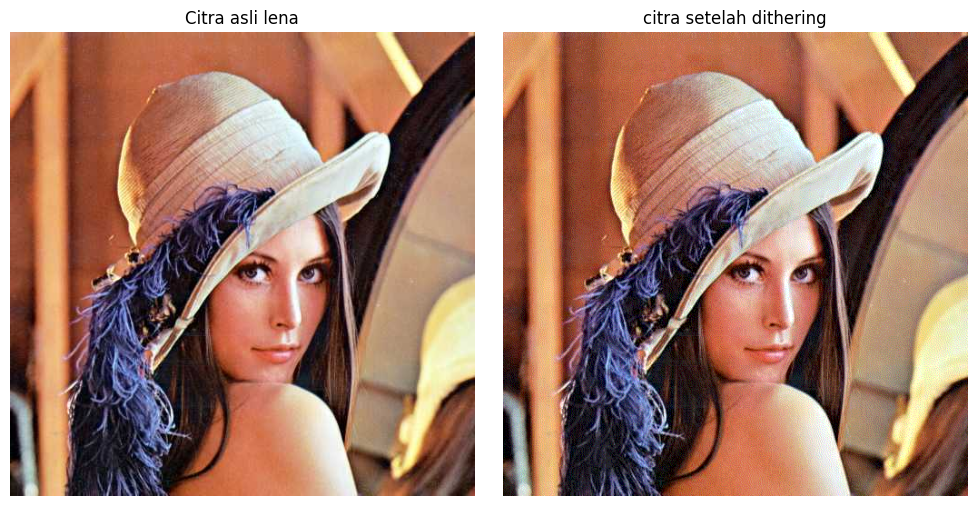

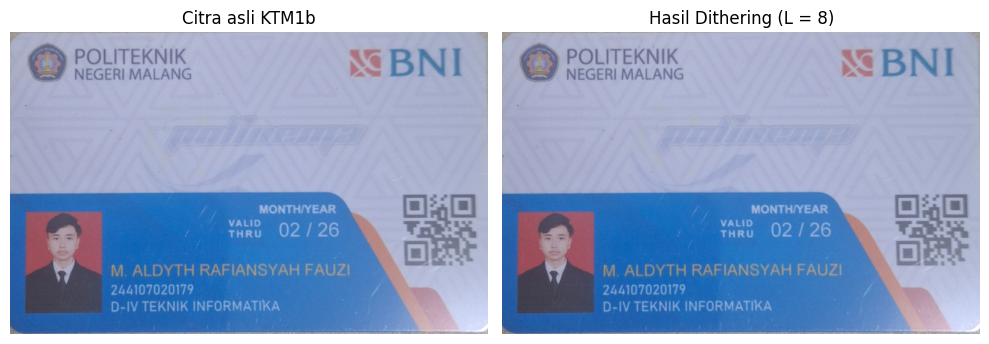

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

PARAM = {'bins': 64, 'clip': 2.0, 'tile': 3, 'L': 8}
BASE_PATH = '/content/drive/MyDrive/PCVK2026'


def floyd_steinberg_dithering_channel(channel, levels):
  img = channel.copy().astype(np.float64)
  height, width = img.shape
  step = 255.0 / (levels - 1)

  for y in range(height):
    for x in range(width):
      old_val = img[y, x]
      new_val = np.round(old_val / step) * step
      img[y, x] = new_val
      error = old_val - new_val

      if x + 1 < width:
        img[y, x + 1] += error * (7.0 / 16.0)
      if x - 1 >= 0 and y + 1 < height:
        img[y + 1, x - 1] += error * (3.0 / 16.0)
      if y + 1 < height:
        img[y + 1, x] += error * (5.0 / 16.0)
      if x + 1 < width and y + 1 < height:
        img[y + 1, x + 1] += error * (1.0 / 16.0)

  return np.clip(img, 0, 255).astype(np.uint8)


def floyd_steinberg_dithering(image, levels):
  # Jika citra memiliki 3 kanal warna (RGB/BGR)
  if len(image.shape) == 3:
    channels = cv.split(image)
    dithered_channels = [
        floyd_steinberg_dithering_channel(ch, levels) for ch in channels
    ]
    return cv.merge(dithered_channels)
  else:
    return floyd_steinberg_dithering_channel(image, levels)


# TAHAP 1: PADA lena.jpg (Berwarna)
path_lena = f'{BASE_PATH}/lena.jpg'
lena_bgr = cv.imread(path_lena)

if lena_bgr is None:
  print('Gagal membaca lena.jpg!')
else:
  lena_rgb = cv.cvtColor(lena_bgr, cv.COLOR_BGR2RGB)

  lena_dithered_rgb = floyd_steinberg_dithering(lena_rgb, levels=PARAM['L'])

  fig, axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].imshow(lena_rgb)
  axs[0].set_title('Citra asli lena')
  axs[0].axis('off')

  axs[1].imshow(lena_dithered_rgb)
  axs[1].set_title('citra setelah dithering')
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()

# TAHAP 2: PADA KTM1b.jpg (Sesuai mode citra asli)
path_ktm = f'{BASE_PATH}/KTM1b.jpg'
ktm_bgr = cv.imread(path_ktm)

if ktm_bgr is None:
  print('Gagal membaca KTM1b.jpg!')
else:
  ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
  ktm_dithered_rgb = floyd_steinberg_dithering(ktm_rgb, levels=PARAM['L'])

  fig, axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].imshow(ktm_rgb)
  axs[0].set_title('Citra asli KTM1b')
  axs[0].axis('off')

  axs[1].imshow(ktm_dithered_rgb)
  axs[1].set_title(f"Hasil Dithering (L = {PARAM['L']})")
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()

NO 2


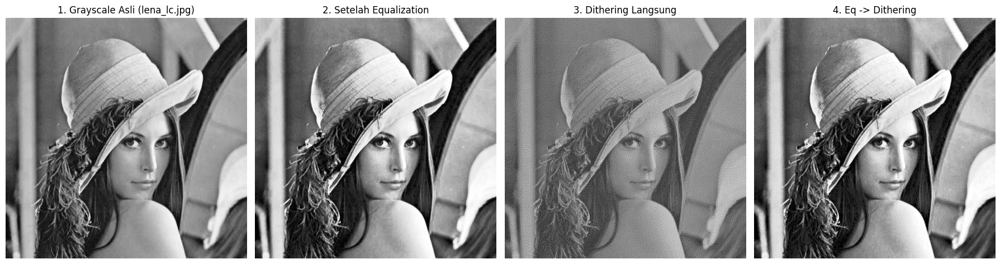

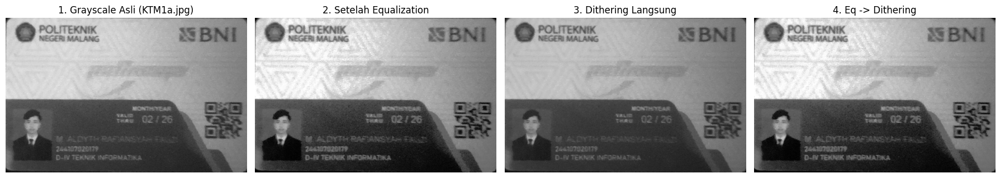

In [7]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

PARAM = {'bins': 64, 'clip': 2.0, 'tile': 3, 'L': 8}
BASE_PATH = '/content/drive/MyDrive/PCVK2026'


def floyd_steinberg_dithering_gray(img_gray, levels):
  img = img_gray.copy().astype(np.float64)
  height, width = img.shape
  step = 255.0 / (levels - 1)

  for y in range(height):
    for x in range(width):
      old_val = img[y, x]
      new_val = np.round(old_val / step) * step
      img[y, x] = new_val
      error = old_val - new_val

      if x + 1 < width:
        img[y, x + 1] += error * (7.0 / 16.0)
      if x - 1 >= 0 and y + 1 < height:
        img[y + 1, x - 1] += error * (3.0 / 16.0)
      if y + 1 < height:
        img[y + 1, x] += error * (5.0 / 16.0)
      if x + 1 < width and y + 1 < height:
        img[y + 1, x + 1] += error * (1.0 / 16.0)

  return np.clip(img, 0, 255).astype(np.uint8)


def proses_pipeline_dithering(path_gambar, title_name):
  img_bgr = cv.imread(path_gambar)
  if img_bgr is None:
    print(f'Gagal membaca {path_gambar}!')
    return

  # Konversi ke Grayscale
  gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

  # Histogram Equalization
  gray_eq = cv.equalizeHist(gray)

  # 3a. Dithering Langsung (Tanpa Ekualisasi)
  dither_direct = floyd_steinberg_dithering_gray(gray, levels=PARAM['L'])

  # 3b. Dithering Setelah Ekualisasi
  dither_after_eq = floyd_steinberg_dithering_gray(gray_eq, levels=PARAM['L'])

  fig, axs = plt.subplots(1, 4, figsize=(18, 5))
  axs[0].imshow(gray, cmap='gray')
  axs[0].set_title(f'1. Grayscale Asli ({title_name})')
  axs[0].axis('off')

  axs[1].imshow(gray_eq, cmap='gray')
  axs[1].set_title('2. Setelah Equalization')
  axs[1].axis('off')

  axs[2].imshow(dither_direct, cmap='gray')
  axs[2].set_title('3. Dithering Langsung')
  axs[2].axis('off')

  axs[3].imshow(dither_after_eq, cmap='gray')
  axs[3].set_title('4. Eq -> Dithering')
  axs[3].axis('off')

  plt.tight_layout()
  plt.show()


# Tahap 1: lena_lc.jpg
proses_pipeline_dithering(f'{BASE_PATH}/lena_lc.jpg', 'lena_lc.jpg')

# Tahap 2: KTM1a.jpg
proses_pipeline_dithering(f'{BASE_PATH}/KTM1a.jpg', 'KTM1a.jpg')

Penjelasan Perbandingan

1. Analisis Keterbacaan Teks pada KTM (KTM1a.jpg)
- Urutan Terbaik: Histogram Equalization terlebih dahulu, baru kemudian Dithering (Eq -> Dithering).

2. Alasan Mengapa Urutan Eq -> Dithering Lebih Terbaca
- Dithering Langsung Tanpa Ekualisasi: Citra asli KTM1a memiliki kondisi pencahayaan yang gelap dan kontras rendah. Jika dithering diterapkan secara langsung, rentang nilai intensitas piksel yang sempit akan dipaksa dikuantisasi ke level L. Akibatnya, teks NIM dan Nama menjadi samar dan tertutup bintik-bintik dither yang menumpuk.
- Ekualisasi Dulu Baru Dithering: Proses histogram equalization merentangkan dan meratakan distribusi intensitas piksel terlebih dahulu, sehingga kontras antara teks dan latar belakang meningkat tajam. Saat dithering diterapkan setelahnya, algoritma memiliki rentang kontras yang cukup luas untuk memisahkan karakter teks dari latar belakang, menjadikan teks NIM dan Nama jauh lebih tegas dan mudah dibaca.